# TASK 06 — Content-Based TF-IDF + Cosine Similarity

Bu defter, proje kitapçığındaki ikinci model olarak film başlığı ve tür metaverisini kullanan içerik tabanlı bir sıralayıcı kurar. Değerlendirme, `config.yaml` içindeki zaman kesmesi, kullanıcılar, aday evreni ve görülen öğe politikasıyla aynıdır.

**Sızıntı önlemi:** Model özellik sözlüğü ve IDF ağırlıkları yalnızca 2020 öncesinde eğitimde görülen filmlerin metaverisiyle öğrenilir. Test puanları yalnızca son değerlendirmede hedef olarak kullanılır. Tam 84.432 öğelik rated-movies evreni yapılandırmadaki ortak protokol gereği tutulur; test etkileşimleri model veya eşik seçmek için kullanılmaz. Pozitif kullanıcı tercihleri eğitim puanı **≥ 4.0** olarak tanımlanır.


## 1. Ortam, yapılandırma ve veri bütünlüğü

Yolları `config.yaml` dosyasından al; MovieLens kaynak CSV’lerini salt okunur aç. Seed yalnızca deterministik işlemler için kullanılır. Yoğun kullanıcı-film matrisi oluşturulmaz.


In [1]:
import os
import sys
import yaml
import time
import csv
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.sparse import csr_matrix
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import normalize
from IPython.display import display

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

cwd = os.getcwd()
project_root = os.path.abspath(os.path.join(cwd, '..')) if os.path.basename(cwd) == 'notebooks' else os.path.abspath(cwd)
with open(os.path.join(project_root, 'config.yaml'), encoding='utf-8') as f:
    config = yaml.safe_load(f)
dataset_dir = config['dataset']['directory']
ratings_path = os.path.join(dataset_dir, config['dataset']['ratings'])
movies_path = os.path.join(dataset_dir, config['dataset']['movies'])
results_path = os.path.join(project_root, 'results')
figures_path = os.path.join(results_path, 'figures')
os.makedirs(figures_path, exist_ok=True)

cutoff = int(config['evaluation']['temporal_split']['cutoff_timestamp'])
expected_users = int(config['evaluation']['evaluable_users']['count'])
expected_items = int(config['evaluation']['candidate_universe']['total_items'])
print(f'Project root: {project_root}')
print(f'Dataset: {dataset_dir}')
print(f'Cutoff: {config["evaluation"]["temporal_split"]["cutoff_utc"]} ({cutoff})')
assert os.path.isfile(ratings_path) and os.path.isfile(movies_path), 'MovieLens source CSV files are missing.'


Project root: C:\OneriAlgoritmalariProjesi
Dataset: C:/ml-32m
Cutoff: 2020-01-01 00:00:00 UTC (1577836800)


## 2. Zamansal ayrım ve ortak değerlendirme evreni

Eğitim etkileşimleri `timestamp < cutoff`; test etkileşimleri `timestamp >= cutoff` biçiminde ayrılır. Metrikler yalnızca config içindeki değerlendirilebilir kullanıcılar üzerinde hesaplanır. Kullanıcı hedefleri test dönemindeki tekil film kimlikleridir; her kullanıcının eğitimde gördüğü filmler adaylardan çıkarılır.


In [2]:
t0 = time.time()
dtypes = {'userId': 'int32', 'movieId': 'int32', 'rating': 'float32', 'timestamp': 'int32'}
ratings = pd.read_csv(ratings_path, usecols=['userId', 'movieId', 'rating', 'timestamp'], dtype=dtypes)
movies = pd.read_csv(movies_path, usecols=['movieId', 'title', 'genres'], dtype={'movieId': 'int32'})
train = ratings.loc[ratings['timestamp'] < cutoff].copy()
test = ratings.loc[ratings['timestamp'] >= cutoff].copy()
train_items = np.sort(train['movieId'].unique())
candidate_items = np.sort(ratings['movieId'].unique())
train_users = set(train['userId'].unique())
test_users = set(test['userId'].unique())
evaluable_users = np.array(sorted(train_users & test_users), dtype=np.int32)

test_eval = test.loc[test['userId'].isin(evaluable_users)]
train_eval = train.loc[train['userId'].isin(evaluable_users)]
targets = test_eval.groupby('userId', sort=True)['movieId'].apply(set).to_dict()
seen = train_eval.groupby('userId', sort=True)['movieId'].apply(set).to_dict()

assert int(train['timestamp'].max()) < int(test['timestamp'].min()), 'Temporal leakage: train/test timestamp ranges overlap.'
assert len(evaluable_users) == expected_users == 7817, f'Unexpected evaluable user count: {len(evaluable_users)}'
assert len(candidate_items) == expected_items == 84432, f'Unexpected candidate count: {len(candidate_items)}'
assert len(train) + len(test) == len(ratings)
assert all(not (targets[u] & seen[u]) for u in evaluable_users), 'A test target was removed by seen-item exclusion.'
print(f'Ratings loaded: {len(ratings):,}; train: {len(train):,}; test: {len(test):,}')
print(f'Evaluable users: {len(evaluable_users):,}; candidate universe: {len(candidate_items):,}')
print(f'Test interactions for evaluable users: {len(test_eval):,}; load/split seconds: {time.time()-t0:.1f}')


Ratings loaded: 32,000,204; train: 27,364,974; test: 4,635,230
Evaluable users: 7,817; candidate universe: 84,432
Test interactions for evaluable users: 879,024; load/split seconds: 4.6


## 3. Film metinleri ve TF-IDF özellikleri

Film metni başlıktan ve türlerden oluşur. Boş veya `(no genres listed)` tür alanı yok sayılır. TF-IDF sözlüğü ve IDF yalnızca eğitimde yer alan filmlerde `fit` edilir; bütün ortak aday filmlere aynı dönüşüm `transform` ile uygulanır. Böylece test döneminde ilk kez görülen filmler, öğrenilmiş sözlükteki terimleri paylaşıyorlarsa içerikten puan alabilir.


In [3]:
candidate_frame = pd.DataFrame({'movieId': candidate_items})
metadata = candidate_frame.merge(movies, on='movieId', how='left', validate='one_to_one')
metadata['title'] = metadata['title'].fillna('').astype(str).str.strip()
metadata['genres'] = metadata['genres'].fillna('').astype(str).str.strip()
genre_clean = metadata['genres'].where(~metadata['genres'].str.lower().isin(['', '(no genres listed)', 'no genres listed']), '')
metadata['content'] = (metadata['title'] + ' ' + genre_clean).str.strip()
metadata['has_title'] = metadata['title'].ne('')
metadata['has_genre'] = genre_clean.ne('')

train_item_set = set(train_items.tolist())
metadata['seen_in_train'] = metadata['movieId'].isin(train_item_set)
train_doc_mask = metadata['seen_in_train'].to_numpy() & metadata['content'].ne('').to_numpy()
vectorizer = TfidfVectorizer(lowercase=True, stop_words='english', ngram_range=(1, 2), min_df=1, dtype=np.float32)
vectorizer.fit(metadata.loc[train_doc_mask, 'content'])
X = vectorizer.transform(metadata['content']).tocsr().astype(np.float32)
feature_valid = np.diff(X.indptr) > 0

metadata_summary = pd.DataFrame([
    {'Group': 'All rated candidates', 'Items': len(metadata), 'With title': int(metadata['has_title'].sum()), 'With usable genre': int(metadata['has_genre'].sum()), 'Nonzero TF-IDF vector': int(feature_valid.sum())},
    {'Group': 'Seen in train', 'Items': int(metadata['seen_in_train'].sum()), 'With title': int((metadata['seen_in_train'] & metadata['has_title']).sum()), 'With usable genre': int((metadata['seen_in_train'] & metadata['has_genre']).sum()), 'Nonzero TF-IDF vector': int((metadata['seen_in_train'].to_numpy() & feature_valid).sum())},
    {'Group': 'Unseen in train (cold items)', 'Items': int((~metadata['seen_in_train']).sum()), 'With title': int(((~metadata['seen_in_train']) & metadata['has_title']).sum()), 'With usable genre': int(((~metadata['seen_in_train']) & metadata['has_genre']).sum()), 'Nonzero TF-IDF vector': int(((~metadata['seen_in_train']).to_numpy() & feature_valid).sum())},
])
display(metadata_summary)
print(f'Vocabulary size (fit on train-item metadata only): {len(vectorizer.vocabulary_):,}')
print(f'No title: {(~metadata.has_title).sum():,}; no usable genres: {(~metadata.has_genre).sum():,}; empty/zero TF-IDF vectors: {(~feature_valid).sum():,}')


,Group,Items,With title,With usable genre,Nonzero TF-IDF vector
0,All rated candidates,84432,84432,77877,84404
1,Seen in train,59952,59952,55295,59951
2,Unseen in train (cold items),24480,24480,22582,24453


Vocabulary size (fit on train-item metadata only): 153,282
No title: 0; no usable genres: 6,555; empty/zero TF-IDF vectors: 28


## 4. Pozitif tercih profilleri ve kişiselleştirilmiş sıralama

Her kullanıcının profili, yalnızca eğitim döneminde puanı en az 4.0 olan filmlerin TF-IDF vektörlerinin eşit ağırlıklı toplamının L2-normalize edilmiş halidir. Bu profil ile her aday filmin TF-IDF vektörü arasındaki kosinüs benzerliği sıralama skorudur. Skorlar kullanıcı grupları halinde seyrek matris çarpımıyla üretilir; yoğun 7.817 × 84.432 skor matrisi belleğe alınmaz.

Eşit skorlarda film kimliği küçük olan önce gelir. Pozitif benzerlikli adaylar bitince, matematiksel kosinüs skoru 0 olan uygun adaylar bu deterministik sırayla listeyi 10’a tamamlayabilir. Eğitimde pozitif puanı bulunmayan kullanıcılara yapay profil atanmaz ve öneri listesi boş kalır.


In [4]:
item_to_idx = {int(mid): i for i, mid in enumerate(candidate_items)}
user_to_row = {int(uid): i for i, uid in enumerate(evaluable_users)}
pos = train_eval.loc[train_eval['rating'] >= 4.0, ['userId', 'movieId']]
pos_rows = pos['userId'].map(user_to_row).to_numpy(dtype=np.int32)
pos_cols = pos['movieId'].map(item_to_idx).to_numpy(dtype=np.int32)
positive_ui = csr_matrix((np.ones(len(pos), dtype=np.float32), (pos_rows, pos_cols)), shape=(len(evaluable_users), len(candidate_items)), dtype=np.float32)
profiles = normalize(positive_ui @ X, norm='l2', axis=1, copy=False).tocsr().astype(np.float32)
profile_available = np.diff(profiles.indptr) > 0
positive_counts = np.asarray(positive_ui.sum(axis=1)).ravel().astype(np.int32)

seen_idx = {}
for uid in evaluable_users:
    seen_idx[int(uid)] = {item_to_idx[int(mid)] for mid in seen.get(int(uid), set())}
# Test hedefleri de aday indekslerine dönüştürülür; yalnızca değerlendirmede kullanılır.
target_idx = {int(uid): {item_to_idx[int(mid)] for mid in targets.get(int(uid), set())} for uid in evaluable_users}
cold_global = ~metadata['seen_in_train'].to_numpy()

recommendations = {}
zero_fill_counts = []
batch_size = 64
for start in range(0, len(evaluable_users), batch_size):
    stop = min(start + batch_size, len(evaluable_users))
    score_block = (profiles[start:stop] @ X.T).tocsr()
    for local_row, uid in enumerate(evaluable_users[start:stop]):
        uid = int(uid)
        if not profile_available[start + local_row]:
            recommendations[uid] = []
            zero_fill_counts.append(0)
            continue
        row = score_block.getrow(local_row)
        idx = row.indices
        vals = row.data
        keep = ~np.isin(idx, np.fromiter(seen_idx[uid], dtype=np.int32, count=len(seen_idx[uid])))
        idx, vals = idx[keep], vals[keep]
        order = np.lexsort((idx, -vals))
        chosen = idx[order[:10]].tolist()
        positive_selected = set(chosen)
        zero_fill = 0
        if len(chosen) < 10:
            need = 10 - len(chosen)
            scan_n = min(len(candidate_items), len(seen_idx[uid]) + 10 + len(chosen))
            zero_candidates = np.arange(scan_n, dtype=np.int32)
            zero_candidates = zero_candidates[~np.isin(zero_candidates, np.fromiter(seen_idx[uid], dtype=np.int32, count=len(seen_idx[uid])))]
            if positive_selected:
                zero_candidates = zero_candidates[~np.isin(zero_candidates, np.fromiter(positive_selected, dtype=np.int32))]
            fill = zero_candidates[:need].tolist()
            chosen.extend(fill)
            zero_fill = len(fill)
        recommendations[uid] = chosen
        zero_fill_counts.append(zero_fill)
print(f'Users with positive-profile vector: {int(profile_available.sum()):,}/{len(evaluable_users):,}')
print(f'Positive training interactions (rating >= 4.0): {len(pos):,}')
print(f'Recommendation lists with 10 items: {sum(len(v)==10 for v in recommendations.values()):,}/{len(evaluable_users):,}')
print(f'Zero-score fallback slots across lists: {sum(zero_fill_counts):,}')


Users with positive-profile vector: 7,807/7,817
Positive training interactions (rating >= 4.0): 1,585,513
Recommendation lists with 10 items: 7,807/7,817
Zero-score fallback slots across lists: 0


## 5. Test metrikleri ve soğuk öğe analizi

Metrikler TASK 05 ile aynı makro kullanıcı ortalaması tanımını kullanır: Precision@10 hit sayısı/10, Recall@10 hit sayısı/kullanıcının test hedefi sayısı, NDCG@10 ikili relevance ile ve ideal DCG aynı hedef kümesinden hesaplanır. Coverage@10, en az bir kez önerilen farklı filmlerin sayısı / 84.432 ortak adaydır.

Soğuk öğeler, 2020 öncesi eğitimde hiç görülmeyen ancak rated-movies ortak evreninde bulunan filmlerdir. Ek olarak yalnızca bu öğelerden oluşan test hedefleriyle cold-item Precision/Recall/NDCG; aday evrenindeki soğuk filmlerden önerilenlerin sayısı ve TF-IDF ile skorlanabilir metaveri kapsamı raporlanır. Cold Recall tavanı, cold hedeflerin tümü önerilebilir kabul edildiğinde 1.0’dır; bu model kapasitesi iddiası değil, hedef kümesinin paydasıdır.


In [5]:
def ranking_metrics(target_map, rec_map, user_ids, k=10):
    p_vals, r_vals, n_vals = [], [], []
    all_rec = set()
    for uid in user_ids:
        uid = int(uid)
        truth = target_map.get(uid, set())
        rec = rec_map.get(uid, [])[:k]
        all_rec.update(rec)
        hits = np.array([1.0 if item in truth else 0.0 for item in rec], dtype=np.float64)
        p_vals.append(float(hits.sum() / k))
        r_vals.append(float(hits.sum() / len(truth)) if truth else 0.0)
        dcg = float(np.sum(hits / np.log2(np.arange(2, len(hits) + 2)))) if len(hits) else 0.0
        ideal_n = min(len(truth), k)
        idcg = float(np.sum(1.0 / np.log2(np.arange(2, ideal_n + 2)))) if ideal_n else 0.0
        n_vals.append(dcg / idcg if idcg else 0.0)
    return {'Precision@10': float(np.mean(p_vals)), 'Recall@10': float(np.mean(r_vals)), 'NDCG@10': float(np.mean(n_vals)), 'Coverage@10': len(all_rec)/len(candidate_items), 'Unique_Recs': len(all_rec), 'recommended_set': all_rec}

all_metrics = ranking_metrics(target_idx, recommendations, evaluable_users)
cold_targets = {int(uid): target_idx[int(uid)] & set(np.flatnonzero(cold_global).tolist()) for uid in evaluable_users}
cold_metrics = ranking_metrics(cold_targets, recommendations, evaluable_users)
cold_test_interactions = int((~test_eval['movieId'].isin(train_items)).sum())
all_eval_interactions = int(len(test_eval))
recommended_cold = all_metrics['recommended_set'] & set(np.flatnonzero(cold_global).tolist())
scoreable_cold_count = int((cold_global & feature_valid).sum())
profile_rate = float(profile_available.mean())
metadata_rate = float(feature_valid.mean())

metrics_row = {
    'Model': 'Content-Based TF-IDF + Cosine Similarity',
    'Precision@10': round(all_metrics['Precision@10'], 6),
    'Recall@10': round(all_metrics['Recall@10'], 6),
    'NDCG@10': round(all_metrics['NDCG@10'], 6),
    'Coverage@10': f"{all_metrics['Coverage@10']*100:.3f}%",
    'Benzersiz_Oneri_Sayisi': all_metrics['Unique_Recs'],
    'Model_Kapasitesi': f"{int(feature_valid.sum()):,}/{len(candidate_items):,} TF-IDF-vector items ({metadata_rate*100:.2f}%)",
    'Parametreler': 'title+genres; word 1-2 grams; min_df=1; fit on train-item metadata; positive rating>=4.0; top10',
    'Notlar': f"U_eval=7,817; test>=2020-01-01; seen excluded; cold-target Recall@10={cold_metrics['Recall@10']:.6f}; cold items recommended={len(recommended_cold):,}/{int(cold_global.sum()):,}; user-profile coverage={profile_rate*100:.2f}%"
}
metric_display = pd.DataFrame([
    {'Metric': key, 'Value': all_metrics[key]} for key in ['Precision@10','Recall@10','NDCG@10','Coverage@10','Unique_Recs']
])
display(metric_display)
cold_summary = pd.DataFrame([
    {'Measure': 'Unseen-in-train candidates', 'Count': int(cold_global.sum()), 'Rate': f"{cold_global.mean()*100:.2f}%"},
    {'Measure': 'Cold candidates with nonzero TF-IDF vector', 'Count': scoreable_cold_count, 'Rate': f"{scoreable_cold_count/max(1,int(cold_global.sum()))*100:.2f}% of cold items"},
    {'Measure': 'Cold test interactions among evaluable users', 'Count': cold_test_interactions, 'Rate': f"{cold_test_interactions/all_eval_interactions*100:.2f}% of evaluable test interactions"},
    {'Measure': 'Unique cold items recommended at least once', 'Count': len(recommended_cold), 'Rate': f"{len(recommended_cold)/max(1,int(cold_global.sum()))*100:.2f}% of cold items"},
    {'Measure': 'Evaluable users with positive profile', 'Count': int(profile_available.sum()), 'Rate': f"{profile_rate*100:.2f}%"},
])
display(cold_summary)
print(f"Cold-target metrics (full Top-10 ranked list): Precision@10={cold_metrics['Precision@10']:.6f}, Recall@10={cold_metrics['Recall@10']:.6f}, NDCG@10={cold_metrics['NDCG@10']:.6f}")
print(f"Cold test interactions: {cold_test_interactions:,}/{all_eval_interactions:,} ({cold_test_interactions/all_eval_interactions*100:.2f}%)")


,Metric,Value
0,Precision@10,0.009070
1,Recall@10,0.000915
2,NDCG@10,0.008778
3,Coverage@10,0.019673
4,Unique_Recs,1661.000000


,Measure,Count,Rate
0,Unseen-in-train candidates,24480,28.99%
1,Cold candidates with nonzero TF-IDF vector,24453,99.89% of cold items
2,Cold test interactions among evaluable users,152122,17.31% of evaluable test interactions
3,Unique cold items recommended at least once,1121,4.58% of cold items
4,Evaluable users with positive profile,7807,99.87%


Cold-target metrics (full Top-10 ranked list): Precision@10=0.008162, Recall@10=0.003526, NDCG@10=0.008379
Cold test interactions: 152,122/879,024 (17.31%)


## 6. Görselleştirme ve temel model kıyası

Üst panelde resmi TASK 05 popülerlik satırlarıyla aynı test protokolündeki sıralama metrikleri ve kapsama gösterilir. Alt panel, TF-IDF modelinin cold test hedeflerine erişimini ve 2020 öncesi eğitimde görülmeyen adayların metaveri vektörü kapsamını gösterir. Grafik yeni metrik üretmez; yukarıdaki hesaplanmış değerleri görselleştirir.


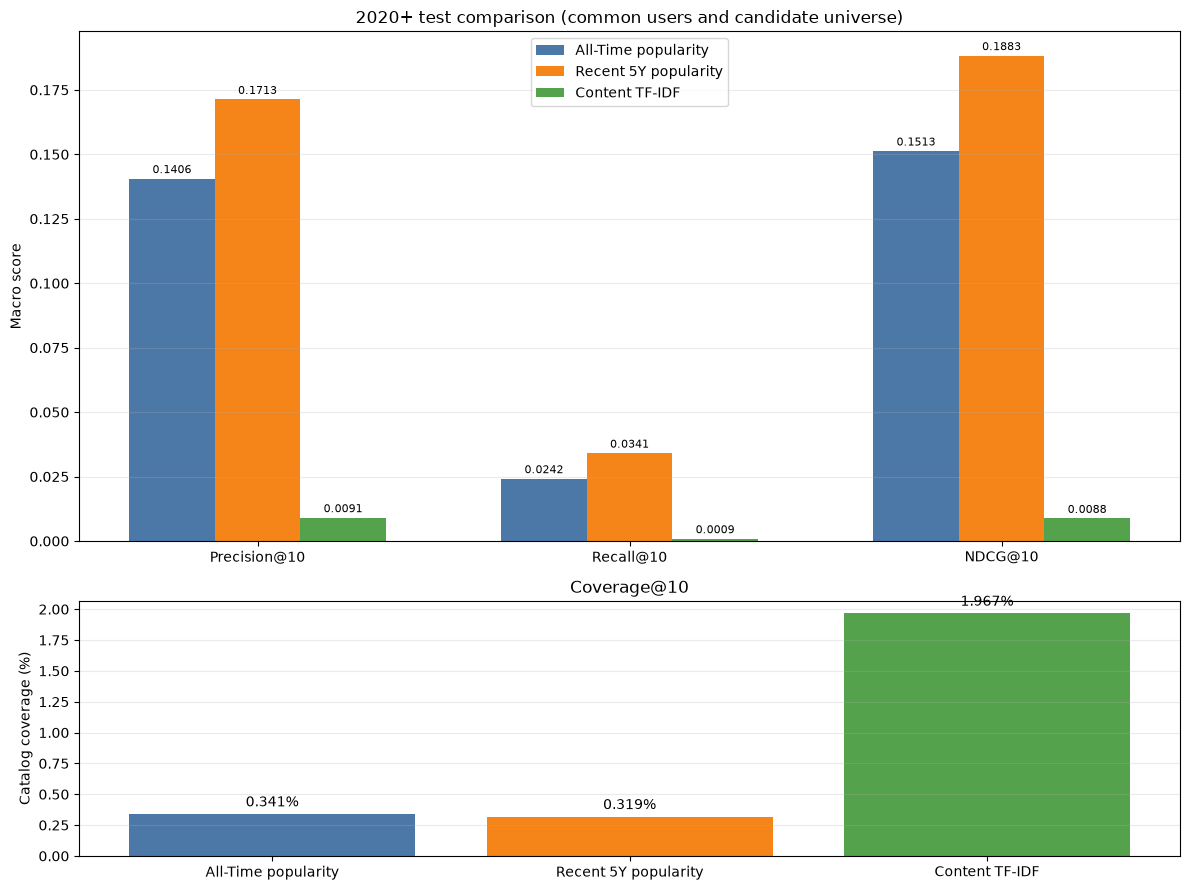

Saved: C:\OneriAlgoritmalariProjesi\results\figures\content_tfidf_comparison.png


In [6]:
results_csv = os.path.join(results_path, 'sonuclar.csv')
prior = pd.read_csv(results_csv, encoding='utf-8-sig')
baselines = prior[prior['Model'].isin(['Adjusted Popularity (All-Time, 1995-2019)', 'Adjusted Popularity (Recent 5 Years, 2015-2019)'])].copy()
assert len(baselines) == 2, 'Expected both official TASK 05 baseline rows in results/sonuclar.csv.'
models = list(baselines['Model']) + [metrics_row['Model']]
metric_values = {
    'Precision@10': [float(baselines.iloc[i]['Precision@10']) for i in range(2)] + [all_metrics['Precision@10']],
    'Recall@10': [float(baselines.iloc[i]['Recall@10']) for i in range(2)] + [all_metrics['Recall@10']],
    'NDCG@10': [float(baselines.iloc[i]['NDCG@10']) for i in range(2)] + [all_metrics['NDCG@10']],
}
coverage_values = [float(str(v).replace('%','')) for v in baselines['Coverage@10']] + [all_metrics['Coverage@10']*100]
short_names = ['All-Time popularity', 'Recent 5Y popularity', 'Content TF-IDF']
fig, axes = plt.subplots(2, 1, figsize=(12, 9), gridspec_kw={'height_ratios':[2,1]})
x = np.arange(len(metric_values)); width = 0.23
colors = ['#4c78a8','#f58518','#54a24b']
for j, name in enumerate(short_names):
    vals = [metric_values[m][j] for m in metric_values]
    bars = axes[0].bar(x + (j-1)*width, vals, width, label=name, color=colors[j])
    axes[0].bar_label(bars, fmt='%.4f', padding=2, fontsize=8)
axes[0].set_xticks(x); axes[0].set_xticklabels(list(metric_values))
axes[0].set_ylabel('Macro score'); axes[0].set_title('2020+ test comparison (common users and candidate universe)')
axes[0].legend(); axes[0].grid(axis='y',alpha=.25)
bars=axes[1].bar(short_names, coverage_values, color=colors)
axes[1].bar_label(bars, labels=[f'{v:.3f}%' for v in coverage_values], padding=3)
axes[1].set_ylabel('Catalog coverage (%)'); axes[1].set_title('Coverage@10')
axes[1].grid(axis='y',alpha=.25)
fig.tight_layout()
comparison_figure = os.path.join(figures_path, 'content_tfidf_comparison.png')
fig.savefig(comparison_figure, dpi=300, bbox_inches='tight')
plt.show()
print(f'Saved: {comparison_figure}')


## 7. Sonuçları koruyarak CSV’ye ekleme

Yeni model satırı mevcut CSV’nin sonuna eklenir; önceki satırlar silinmez veya yeniden hesaplanmaz. Aynı model adı zaten varsa işlem durur, böylece notebook’un tekrar çalıştırılması sessizce mükerrer satır oluşturmaz.


In [7]:
existing_models = set(prior['Model'].astype(str))
assert metrics_row['Model'] not in existing_models, 'TASK 06 result already exists in CSV; refusing to append a duplicate row.'
with open(results_csv, 'a', encoding='utf-8', newline='') as f:
    writer = csv.DictWriter(f, fieldnames=list(prior.columns), extrasaction='raise')
    writer.writerow(metrics_row)
updated = pd.read_csv(results_csv, encoding='utf-8-sig')
assert len(updated) == len(prior) + 1
assert updated.iloc[-1]['Model'] == metrics_row['Model']
print(f'Appended one row; existing rows preserved: {len(prior)} -> {len(updated)}')
display(updated.tail(4))


Appended one row; existing rows preserved: 3 -> 4


,Model,Precision@10,Recall@10,NDCG@10,Coverage@10,Benzersiz_Oneri_Sayisi,Model_Kapasitesi,Parametreler,Notlar
0,[Ön Aday / Test-Tuned] Adjusted Popularity Bas...,0.13880,0.024800,0.148000,0.327%,276,71.01% (59952/84432),"beta=50000, cutoff=2020-01-01, k_core=0",Eski test-tuned denemesi; sızıntılı beta seçim...
1,"Adjusted Popularity (All-Time, 1995-2019)",0.14060,0.024200,0.151300,0.341%,288,"71.01% (59,952/84,432)","beta=1000000, cutoff=2020-01-01, window=1995-2019",Resmi Benchmark; validation beta=1000000; goru...
2,"Adjusted Popularity (Recent 5 Years, 2015-2019)",0.17130,0.034100,0.188300,0.319%,269,"69.94% (59,050/84,432)","beta=300000, cutoff=2020-01-01, window=2015-2019",Resmi Benchmark; validation beta=300000; gorul...
3,Content-Based TF-IDF + Cosine Similarity,0.00907,0.000915,0.008778,1.967%,1661,"84,404/84,432 TF-IDF-vector items (99.97%)",title+genres; word 1-2 grams; min_df=1; fit on...,"U_eval=7,817; test>=2020-01-01; seen excluded;..."


## 8. Sonuç ve doğrulama durumu

Bu bölümde raporlanan değerler, defter yürütmesinde hesaplanan tek sonuçlardır. Model/özellik seçimi validation veya test metriklerine göre ayarlanmamıştır. Zamansal ayrım assertion’ı train/test sınırını doğrular; test hedefleri yalnızca final ranking değerlendirmesinde kullanılır. Cold-item performansı ve metaveri/TF-IDF kapsamı birlikte yorumlanmalıdır: metaveri vektörü olan cold item içerikten puanlanabilir; vektör üretilemeyen filmler sadece sıfır benzerlikli tie-break sıralamasında kalır.
